# Calculadora de medios de bulbificación — *Zephyranthes advena*

Cuaderno de apoyo para la tesis del Magíster en Ciencias Agropecuarias (Universidad de Chile).

Calcula, para cada uno de los 15 tratamientos del diseño factorial **3 (sacarosa) × 5 (combinaciones BAP/ANA)**, las cantidades de cada componente del medio:

- masa de MS, sacarosa, carbón activado y agar,
- volumen de stock de BAP y de ANA (con **C₁·V₁ = C₂·V₂**),
- aviso cuando un volumen de stock queda bajo el límite de precisión de la micropipeta.

**Cómo usarlo:** edita la celda de parámetros y ejecuta todo (*Entorno de ejecución → Ejecutar todo*).

## 1. Librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

## 2. Parámetros

> Las concentraciones de BAP y ANA de `COMBINACIONES` están en **mg/L** (concentración final en el medio). Los valores dados son los utilizados en el experimento; los volúmenes de stock varían según cuánto medio se prepare, y aquí se ajustan a 200 mL (`V_FINAL_ML`).

In [2]:
# --- Medio base (por litro) ---
MS_G_L = 4.43          # sales MS (g/L)
CARBON_G_L = 1.0       # carbón activado (g/L)
AGAR_G_L = 8.0         # agar (g/L)
PH = 5.7               # pH final (solo informativo)

# --- Volumen final por tratamiento ---
V_FINAL_ML = 200       # mL

# --- Niveles de sacarosa (g/L) ---
SACAROSA_G_L = [30, 60, 90]

# --- Stocks (M) y pesos moleculares (g/mol) ---
STOCK_BAP_M = 0.01     # 10 mM
STOCK_ANA_M = 0.005    # 5 mM
PM_BAP = 225.25
PM_ANA = 186.21

# --- Límite de precisión de la micropipeta (µL) ---
MIN_PIPETA_UL = 20

# --- Combinaciones BAP/ANA (mg/L finales en el medio) ---
COMBINACIONES = {
    "C1": {"BAP_mg_L": 0.0,  "ANA_mg_L": 0.0},
    "C2": {"BAP_mg_L": 1.0,  "ANA_mg_L": 0.1},
    "C3": {"BAP_mg_L": 1.0,  "ANA_mg_L": 0.5},
    "C4": {"BAP_mg_L": 2.0, "ANA_mg_L": 0.1},
    "C5": {"BAP_mg_L": 2.0, "ANA_mg_L": 0.5},
}

## 3. Cálculo por tratamiento

Para cada tratamiento (T0 a T14) se sigue el mismo procedimiento del cuaderno de laboratorio:

1. **µL de stock para 1000 mL de medio:** moles necesarios = `C (mg/L) / PM`, y volumen de stock = moles necesarios / molaridad del stock. Ejemplo: BAP 1,0 mg/L → 443,95 µL por litro.
2. **Escalar al volumen final** por regla de tres: `µL por litro × V_final (mL) / 1000`. Ejemplo: 443,95 µL × 100 mL / 1000 mL = 44,395 µL.
3. Las masas (MS, sacarosa, carbón y agar) se escalan igual: `g/L × V_final (mL) / 1000`.

In [3]:
def ul_stock_por_litro(c_mg_L, pm, stock_M):
    """µL de stock necesarios para 1000 mL de medio.
    mg/L / (g/mol) = mmol/L; dividido por la molaridad (mmol/mL) da mL de stock; x1000 = µL."""
    return c_mg_L / pm / stock_M * 1000


filas = []
n = 0
for sac in SACAROSA_G_L:
    for nombre_comb, conc in COMBINACIONES.items():
        bap_1l = ul_stock_por_litro(conc["BAP_mg_L"], PM_BAP, STOCK_BAP_M)
        ana_1l = ul_stock_por_litro(conc["ANA_mg_L"], PM_ANA, STOCK_ANA_M)
        filas.append({
            "tratamiento": f"T{n}",
            "sacarosa_g_L": sac,
            "combinacion": nombre_comb,
            "BAP_mg_L": conc["BAP_mg_L"],
            "ANA_mg_L": conc["ANA_mg_L"],
            "MS_g": MS_G_L * V_FINAL_ML / 1000,
            "sacarosa_g": sac * V_FINAL_ML / 1000,
            "carbon_g": CARBON_G_L * V_FINAL_ML / 1000,
            "agar_g": AGAR_G_L * V_FINAL_ML / 1000,
            "BAP_stock_uL_1L": bap_1l,                       # µL por 1000 mL
            "ANA_stock_uL_1L": ana_1l,
            "BAP_stock_uL": bap_1l * V_FINAL_ML / 1000,      # µL para V_FINAL_ML
            "ANA_stock_uL": ana_1l * V_FINAL_ML / 1000,
        })
        n += 1

df = pd.DataFrame(filas)

# Marca los volúmenes de stock que son > 0 pero bajo el límite de la micropipeta
def bajo_limite(v):
    return (v > 0) and (v < MIN_PIPETA_UL)

df["alerta_pipeta"] = df.apply(
    lambda r: bajo_limite(r["BAP_stock_uL"]) or bajo_limite(r["ANA_stock_uL"]), axis=1
)
df.round(3)

,tratamiento,sacarosa_g_L,combinacion,BAP_mg_L,ANA_mg_L,MS_g,sacarosa_g,carbon_g,agar_g,BAP_stock_uL_1L,ANA_stock_uL_1L,BAP_stock_uL,ANA_stock_uL,alerta_pipeta
0,T0,30,C1,0.0,0.0,0.886,6.0,0.2,1.6,0.000,0.000,0.00,0.000,False
1,T1,30,C2,1.0,0.1,0.886,6.0,0.2,1.6,443.951,107.406,88.79,21.481,False
2,T2,30,C3,1.0,0.5,0.886,6.0,0.2,1.6,443.951,537.028,88.79,107.406,False
3,T3,30,C4,2.0,0.1,0.886,6.0,0.2,1.6,887.902,107.406,177.58,21.481,False
4,T4,30,C5,2.0,0.5,0.886,6.0,0.2,1.6,887.902,537.028,177.58,107.406,False
5,T5,60,C1,0.0,0.0,0.886,12.0,0.2,1.6,0.000,0.000,0.00,0.000,False
6,T6,60,C2,1.0,0.1,0.886,12.0,0.2,1.6,443.951,107.406,88.79,21.481,False
7,T7,60,C3,1.0,0.5,0.886,12.0,0.2,1.6,443.951,537.028,88.79,107.406,False
8,T8,60,C4,2.0,0.1,0.886,12.0,0.2,1.6,887.902,107.406,177.58,21.481,False
9,T9,60,C5,2.0,0.5,0.886,12.0,0.2,1.6,887.902,537.028,177.58,107.406,False


## 4. Revisión de alertas de pipeteo

In [4]:
alertas = df[df["alerta_pipeta"]]
if alertas.empty:
    print(f"✅ Todos los volúmenes de stock son ≥ {MIN_PIPETA_UL} µL con V_final = {V_FINAL_ML} mL.")
else:
    print(f"⚠️ {len(alertas)} tratamiento(s) con volúmenes de stock bajo {MIN_PIPETA_UL} µL. "
          f"Considera aumentar V_FINAL_ML o diluir el stock.")
    display(alertas[["tratamiento", "BAP_stock_uL", "ANA_stock_uL"]].round(2))

✅ Todos los volúmenes de stock son ≥ 20 µL con V_final = 200 mL.


## 5. Gráfico del diseño experimental

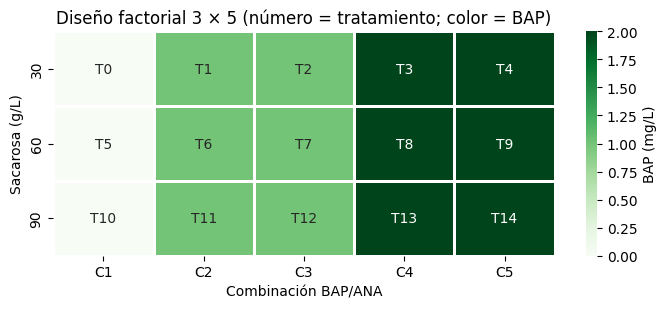

In [5]:
diseno = df.pivot(index="sacarosa_g_L", columns="combinacion", values="tratamiento")
orden = df.pivot(index="sacarosa_g_L", columns="combinacion", values="BAP_mg_L")

fig, ax = plt.subplots(figsize=(7, 3.2))
sns.heatmap(orden, annot=diseno, fmt="", cmap="Greens", cbar_kws={"label": "BAP (mg/L)"},
            linewidths=1, linecolor="white", ax=ax)
ax.set_title("Diseño factorial 3 × 5 (número = tratamiento; color = BAP)")
ax.set_xlabel("Combinación BAP/ANA")
ax.set_ylabel("Sacarosa (g/L)")
plt.tight_layout()
plt.show()

## 6. Stocks: cuánto pesar

Masa necesaria para preparar un volumen de stock a la molaridad indicada, es decir para preparar el stock que se pipetea

In [6]:
def masa_stock_g(molaridad, pm, volumen_ml):
    return molaridad * pm * volumen_ml / 1000

V_STOCK_ML = 100
print(f"BAP {STOCK_BAP_M*1000:.0f} mM: pesar {masa_stock_g(STOCK_BAP_M, PM_BAP, V_STOCK_ML):.4f} g y llevar a {V_STOCK_ML} mL")
print(f"ANA {STOCK_ANA_M*1000:.0f} mM: pesar {masa_stock_g(STOCK_ANA_M, PM_ANA, V_STOCK_ML):.4f} g y llevar a {V_STOCK_ML} mL")

BAP 10 mM: pesar 0.2253 g y llevar a 100 mL
ANA 5 mM: pesar 0.0931 g y llevar a 100 mL


## 7. Exportar resultados

In [7]:
salida = Path("datos")
salida.mkdir(exist_ok=True)
df.round(3).to_csv(salida / "tratamientos.csv", index=False)
print("Guardado en", salida / "tratamientos.csv")

# En Colab, para descargarlo a tu computador:
# from google.colab import files
# files.download("datos/tratamientos.csv")

Guardado en datos/tratamientos.csv


## 8. Opcional: exportar a Word


In [8]:
!pip install python-docx
from docx import Document

doc = Document()
doc.add_heading("Medios de bulbificación — Zephyranthes advena", level=1)
doc.add_paragraph(f"Volumen final por tratamiento: {V_FINAL_ML} mL. pH {PH}.")

columnas = ["tratamiento", "sacarosa_g", "MS_g", "carbon_g", "agar_g", "BAP_stock_uL", "ANA_stock_uL"]
tabla = doc.add_table(rows=1, cols=len(columnas))
tabla.style = "Light Grid Accent 1"
for i, c in enumerate(columnas):
    tabla.rows[0].cells[i].text = c
for _, fila in df[columnas].round(3).iterrows():
    celdas = tabla.add_row().cells
    for i, c in enumerate(columnas):
        celdas[i].text = str(fila[c])

doc.save("medios_bulbificacion.docx")
print("Guardado: medios_bulbificacion.docx")

Guardado: medios_bulbificacion.docx
